# Control A: does the "encoder vs LM" gap survive a like-for-like control?

The first comparison (LLaVA-1.5 vs I-JEPA -> Vicuna) found that JEPA has less decodable "object present" information and answers worse. But the two stacks differ in **training recipe** (LLaVA: projector and LM tuned jointly on instructions; JEPA: projector only, frozen 4-bit LM) as well as in **encoder**. This notebook adds a third arm that removes the recipe difference:

**CLIP ViT-L/14-336 -> the released LLaVA-1.5 *stage-1* projector (trained alone on frozen Vicuna-7B-v1.5) -> the same frozen 4-bit Vicuna-7B-v1.5 as the JEPA model.**

Then LLaVA (full) -> CLIP (projector-only) changes only the recipe, and CLIP (projector-only) -> JEPA changes only the encoder (and the amount of alignment data, see caveats).

**What it runs (about 1-1.5 h on a T4 x2):** model downloads (~15 min), a clean pass and a corrupted pass on the same 1000 POPE object questions with the same measurement code as the first run (last-position DLA components, residual stream), then CPU analysis: matched-sensitivity hallucination, linear probes, prior-only (corrupted-image) measures, and a recipe-vs-encoder decomposition with image-cluster bootstrap CIs. No ablations or patching.

**Attach as inputs:** `encoder-swap-compare` (first run: `llava_clean.npz`, `jepa_clean.npz`), `vlm-questions`, COCO-2014 (`nadaibrahim/coco2014`). Settings: GPU T4 x2, Internet On, secrets `KAGGLE_USERNAME` / `KAGGLE_KEY`. Run the install cell, restart the session, then run everything from the config cell. Outputs go to the dataset `encoder-swap-clip`.

In [1]:
!pip install -q transformers==5.16.1 accelerate==1.14.0 bitsandbytes==0.50.2 pillow==12.3.0 sentencepiece scikit-learn scipy tabulate huggingface_hub 2>&1 | tail -2

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
# 1. CONFIG
import os, re, json, glob, math, time, random, shutil, subprocess, hashlib, gc, warnings
from collections import Counter
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

USERNAME     = "ponishbhatia"                  # the Kaggle account you RUN this notebook from: the checkpoint dataset is pushed to <USERNAME>/encoder-swap-compare (must match the KAGGLE_USERNAME secret)
DATA_OWNER   = "ponishbhatia2"                 # the Kaggle account that OWNS your input datasets (vlm-questions, jepa-projector-fixed-ckpts, dla-jepa-vicuna-noise)
ROHAN        = "nocturnalnerd18"               # Rohan's Kaggle user (dla-llava etc.)
INPUT_ROOT   = os.environ.get("ES_INPUT", "/kaggle/input")
OUT_DIR      = os.environ.get("ES_OUT", "/kaggle/working/encoder_swap")
DATASET_SLUG = "encoder-swap-clip"             # outputs of THIS notebook are pushed here (attach it as an input after a crash to resume)
UPLOAD       = True                            # push checkpoints/results to Kaggle (needs KAGGLE_USERNAME / KAGGLE_KEY in Kaggle secrets)
RESTORE_SLUGS = ["encoder-swap-compare", "encoder-swap-clip"]   # attached datasets whose files are copied into OUT_DIR at start (first run: llava_clean.npz, jepa_clean.npz; this notebook: resume)
PUSH_DIR     = OUT_DIR                         # the folder that is pushed to Kaggle
PUSH_CKPT    = False                           # push checkpoints during long loops
SOFT_FAIL    = True                            # True: a failing cell prints its traceback and the notebook carries on
SEED         = 0


# questions (identical selection procedure to the JEPA runs: same file, same seeds => same question ids)
N_EVAL_FULL  = 1000                            # size of the balanced evaluation list (as in the JEPA notebook)
N_CMP        = 1000                            # questions for the clean pass (DLA, hidden states, behaviour)
N_ABL        = 400                             # step-6 style ablations (the first 400 = the ones used for JEPA)
N_PATCH      = 300                             # step-7 style patching (the first 300 = the ones used for JEPA)
N_MEAN       = 200                             # reference questions for mean activations
N_RANDOM     = 10                              # random control sets per group (as in the JEPA runs)

# CONTROL A: CLIP ViT-L/14-336 -> the LLaVA-1.5 STAGE-1 projector (projector-only training on frozen Vicuna-7B-v1.5) -> the same frozen 4-bit Vicuna as the JEPA model
CLIP_NAME      = "openai/clip-vit-large-patch14-336"
CLIP_PROJ_REPO = "liuhaotian/llava-v1.5-mlp2x-336px-pretrain-vicuna-7b-v1.5"   # stage-1 (projector-only) weights; file mm_projector.bin. If this repo is unreachable, attach a dataset that contains mm_projector.bin
CLIP_PROJ_FILE = "mm_projector.bin"
CLIP_K         = 0.5                           # noise multiplier for the corrupted run: SAME as the JEPA arm (0.5), so prior-only numbers of CLIP and JEPA are directly comparable
CLIP_LAYOUT    = "bos_first"                   # "bos_first" = [BOS][image tokens][text]: how the stage-1 projector was trained.  "jepa" = [image tokens][BOS][text]: how the JEPA projector was trained
PROBE_LAYERS   = list(range(6, 33, 2))         # layers for the linear probes (CPU)
BOOT_B         = 300                           # image-cluster bootstrap draws

# models
LLAVA_NAME   = "llava-hf/llava-1.5-7b-hf"
LLAVA_K      = None                            # None = calibrate on 120 questions so the corrupted AUROC is ~0.5; or set a number
JEPA_K       = 0.5                             # the noise multiplier used for the JEPA results
CKPT_DIR     = f"/kaggle/input/datasets/{DATA_OWNER}/jepa-projector-fixed-ckpts"
CKPT_NAME    = "best.pt"
LLM_PATH     = "lmsys/vicuna-7b-v1.5"
VIT_ID       = "facebook/ijepa_vith16_1k"
PROMPT_JEPA  = "A chat between a curious human and an artificial intelligence assistant. USER: {q} Answer with Yes or No. ASSISTANT:"
IMG_DIR      = "/kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014"                      # POPE images
AMBER_IMAGE_DIR = f"/kaggle/input/datasets/{ROHAN}/amber-hallucination/image"                      # only for HALLUC_TYPE = "attribute" / "relation"
VG_IMAGE_DIRS = ["/kaggle/temp", "/kaggle/temp/VG_100K_2"]                                          # only for relation/reefknot: download Visual Genome first (see Rohan's collect notebook)
HALLUC_TYPE  = "object"                        # "object" = POPE (the full comparison with your earlier JEPA results). "attribute"/"relation" run the same pipeline on the other types (untested; the old-artifact cells are skipped).
QUESTIONS_JSON = f"/kaggle/input/datasets/{DATA_OWNER}/vlm-questions/all_questions.json"

YES_ID, NO_ID = 3869, 1939
EVID_MLPS = ["L16.mlp", "L17.mlp", "L18.mlp", "L20.mlp", "L23.mlp"]
OPP_MLPS  = ["L21.mlp", "L24.mlp", "L27.mlp"]
BRAKE     = ["L28.mlp", "L30.mlp"]
BIAS_HEADS = ["L26H3", "L17H16", "L26H27", "L24H8", "L19H10"]
EVID_HEADS = ["L16H0", "L16H18", "L21H14", "L27H7"]
WINDOWS7  = [(0, 7), (8, 15), (16, 19), (20, 23), (24, 27), (28, 31)]

os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(f"{OUT_DIR}/figs", exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print("output dir:", OUT_DIR)

output dir: /kaggle/working/encoder_swap


In [3]:
# 2. HELPERS: file discovery, questions, statistics, checkpoints, Kaggle push
from scipy.stats import rankdata, spearmanr, norm as _norm

def find_all(name, root=None):
    root = root or INPUT_ROOT
    hits = [p for p in glob.glob(f"{root}/**/*{name}", recursive=True) if os.path.isfile(p)]
    return sorted(hits)
def find1(name, must=None):
    if HALLUC_TYPE != "object" and name in ("meanablation_results.npz", "mlp_localisation.npz", "patching_sweeps.npz", "atp_results.npz"): return None    # old JEPA artifacts exist for POPE only
    hits = find_all(name)
    if must: hits = [h for h in hits if must in h] or hits
    return hits[0] if hits else None

# ---------- statistics ----------
def auroc(x, pos):
    x = np.asarray(x, float); pos = np.asarray(pos, bool); n1, n0 = pos.sum(), (~pos).sum()
    return float((rankdata(x)[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 and n0 else float("nan")
def dprime(x, pos):
    x = np.asarray(x, float); pos = np.asarray(pos, bool)
    sp = np.sqrt((x[pos].var(ddof=1) + x[~pos].var(ddof=1)) / 2); return float((x[pos].mean() - x[~pos].mean()) / sp)
def beh(ld, y):
    ld = np.asarray(ld, float); y = np.asarray(y, bool)
    return dict(n=len(y), auroc=auroc(ld, y), dprime=dprime(ld, y), acc=float(((ld > 0) == y).mean()), yes_rate=float((ld > 0).mean()),
                gap=float(ld[y].mean() - ld[~y].mean()), sd=float(ld.std()), halluc=float((ld[~y] > 0).mean()), miss=float((ld[y] <= 0).mean()))
def boot_idx(n, B=1000, seed=0): return np.random.default_rng(seed).integers(0, n, (B, n))
def ci(v, q=(2.5, 97.5)): return tuple(float(x) for x in np.percentile(v, q))
def fmt_ci(v): lo, hi = ci(v); return f"[{lo:+.3f}, {hi:+.3f}]"

# ---------- questions and evaluation sets (same procedure as the JEPA notebook) ----------
qpath = QUESTIONS_JSON if os.path.exists(QUESTIONS_JSON) else (find1("all_questions.json", must="vlm-questions") or find1("all_questions.json"))
assert qpath, "attach a vlm-questions dataset (all_questions.json, 17492 questions, version 2)"
with open(qpath) as f: all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2 (17492 questions)"
def resolve_path(q):
    qid = q["question_id"]
    if qid.startswith("pope_"): return os.path.join(IMG_DIR, f"{q['image_id']}.jpg")
    if qid.startswith("amber_"): return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    for d in VG_IMAGE_DIRS:
        p = os.path.join(d, f"{q['image_id']}.jpg")
        if os.path.exists(p): return p
    return os.path.join(VG_IMAGE_DIRS[0], f"{q['image_id']}.jpg")
recs = [dict(q, gt=str(q["ground_truth_answer"]).strip().lower(), path=resolve_path(q))
        for q in all_questions if q["hallucination_type"] == HALLUC_TYPE and q["answer_format"] == "yes_no"]
print(f"{len(recs)} {HALLUC_TYPE} yes/no questions | gt: {dict(Counter(r['gt'] for r in recs))} | missing images: {sum(not os.path.exists(r['path']) for r in recs)}")
REC_IDX = {r["question_id"]: j for j, r in enumerate(recs)}
imgpar = lambda r: int(re.findall(r"\d+", str(r["image_id"]))[-1]) % 2
odd = [r for r in recs if imgpar(r) == 1]
_rng = random.Random(SEED)
_ey = [r for r in odd if r["gt"] == "yes"]; _en = [r for r in odd if r["gt"] == "no"]
EVAL = _rng.sample(_ey, min(N_EVAL_FULL // 2, len(_ey))) + _rng.sample(_en, min(N_EVAL_FULL // 2, len(_en))); _rng.shuffle(EVAL)
_rr = random.Random(SEED + 21); _ref_pool = [r for r in recs if imgpar(r) == 0]
REFQ = _rr.sample([r for r in _ref_pool if r["gt"] == "yes"], N_MEAN // 2) + _rr.sample([r for r in _ref_pool if r["gt"] == "no"], N_MEAN // 2)
CMP, EV6, EV7 = EVAL[:N_CMP], EVAL[:N_ABL], EVAL[:N_PATCH]
CAL = [r for r in _ref_pool if r["gt"] == "yes"][-60:] + [r for r in _ref_pool if r["gt"] == "no"][-60:]      # noise calibration set (even images, disjoint from EVAL; may overlap REFQ, harmless)
print(f"EVAL {len(EVAL)} {dict(Counter(r['gt'] for r in EVAL))} | CMP {len(CMP)} | ablation {len(EV6)} | patching {len(EV7)} | mean-reference {len(REFQ)} | calibration {len(CAL)}")

# ---------- checkpoints + Kaggle push ----------
def sh(cmd, timeout=3000):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout); return r.returncode, (r.stdout + r.stderr).strip()
DS_ID = f"{USERNAME}/{DATASET_SLUG}"
os.makedirs(PUSH_DIR, exist_ok=True)
if UPLOAD:
    try:
        from kaggle_secrets import UserSecretsClient
        _s = UserSecretsClient(); os.environ["KAGGLE_USERNAME"] = _s.get_secret("KAGGLE_USERNAME"); os.environ["KAGGLE_KEY"] = _s.get_secret("KAGGLE_KEY")
        with open(f"{PUSH_DIR}/dataset-metadata.json", "w") as f:
            json.dump({"title": DATASET_SLUG, "id": DS_ID, "subtitle": "LLaVA vs JEPA-Vicuna encoder-swap comparison outputs",
                       "description": "Clean-pass DLA/hidden states, mean-ablation and patching results for LLaVA-1.5-7B and the I-JEPA->Vicuna-7B VLM on the same POPE questions.",
                       "licenses": [{"name": "CC0-1.0"}]}, f)
    except Exception as ex:
        print("Kaggle secrets not available, uploads disabled:", ex); UPLOAD = False
def push(note):
    if not UPLOAD: return
    rc, out = sh(["kaggle", "datasets", "status", DS_ID], 120)
    cmd = ["kaggle", "datasets", "create", "-p", PUSH_DIR] if rc != 0 else ["kaggle", "datasets", "version", "-p", PUSH_DIR, "-m", note]
    rc, out = sh(cmd + ["--dir-mode", "zip"]); print(f"[push] {'OK' if rc == 0 else 'FAILED'} ({note}): {out[-160:]}")

def restore_from_input():
    n = 0
    for slug in dict.fromkeys(RESTORE_SLUGS):
        srcs = [d for d in glob.glob(f"{INPUT_ROOT}/**/{slug}", recursive=True) if os.path.isdir(d)]
        if not srcs: print(f"no copy of {slug} attached"); continue
        m = 0
        for f in glob.glob(srcs[0] + "/**/*", recursive=True):
            if not (os.path.isfile(f) and f.endswith((".npz", ".csv", ".json", ".png", ".md"))): continue
            if os.path.basename(f).startswith("ckpt_") and slug != DATASET_SLUG: continue          # checkpoints of another notebook are not needed
            dest = os.path.join(OUT_DIR, os.path.basename(f))
            if not os.path.exists(dest): shutil.copy(f, dest); m += 1
            elif os.path.basename(f).startswith("ckpt_"):
                try:
                    if int(np.load(f)["done"]) > int(np.load(dest)["done"]): shutil.copy(f, dest); m += 1
                except Exception: pass
        print(f"restored {m} files from {srcs[0]}"); n += m
    if not n: print("nothing restored; starting from scratch")
restore_from_input()

def _ckpt_key(labels, qids): return hashlib.md5(("|".join(map(str, labels)) + "#" + "|".join(map(str, qids))).encode()).hexdigest()
def ckpt_load(name, key, arrays):
    p = f"{OUT_DIR}/ckpt_{name}.npz"
    if not os.path.exists(p): return 0
    try:
        z = np.load(p, allow_pickle=False)
        if str(z["key"]) != key or any(z[k].shape != a.shape for k, a in arrays.items()): print(f"[{name}] checkpoint does not match this configuration; restarting"); return 0
        for k, a in arrays.items(): a[...] = z[k]
        print(f"[{name}] resuming from row {int(z['done'])}"); return int(z["done"])
    except Exception as ex: print(f"[{name}] checkpoint unreadable ({ex}); restarting"); return 0
_ck_n = {}
def ckpt_save(name, key, done, arrays, push_every=4):
    p = f"{OUT_DIR}/ckpt_{name}.npz"; tmp = p[:-4] + "_tmp.npz"
    np.savez(tmp, done=done, key=key, **arrays); os.replace(tmp, p)
    _ck_n[name] = _ck_n.get(name, 0) + 1
    if push_every and PUSH_CKPT and _ck_n[name] % push_every == 0: push(f"{name} checkpoint at row {done}")

def load_rohan_dla(full=False):
    """Rohan's dla-llava object batches (qid -> entry). full=False keeps only what is needed for logit differences."""
    import torch
    out = {}
    for fn in find_all(f"{HALLUC_TYPE}_batch_*.pt"):
        if "dla-llava" not in fn or "analysis" in fn: continue
        for e in torch.load(fn, weights_only=False):
            out[e["question_id"]] = e if full else dict(logit_diff=e["logit_diff"], ground_truth_answer=e["ground_truth_answer"])
    return out

3000 object yes/no questions | gt: {'yes': 1500, 'no': 1500} | missing images: 0
EVAL 1000 {'no': 500, 'yes': 500} | CMP 1000 | ablation 400 | patching 300 | mean-reference 200 | calibration 120
restored 12 files from /kaggle/input/datasets/ponishbhatia/encoder-swap-compare
no copy of encoder-swap-clip attached


In [4]:
# 4. WHAT IS ATTACHED? (the cells that need a file skip themselves with a message if it is missing)
EXPECT = [
    ("first run outputs (encoder-swap-compare)", ["llava_clean.npz", "jepa_clean.npz"]),
    ("questions (vlm-questions)", ["all_questions.json"]),
    ("COCO val2014 images", ["COCO_val2014_000000225183.jpg"]),
    ("this notebook's own earlier outputs (optional, resume)", ["clip_clean.npz"]),
    ("stage-1 projector, only if HF is unreachable (optional)", ["mm_projector.bin"]),
]
for grp, names in EXPECT:
    for nm in names:
        hits = find_all(nm); print(f"{'FOUND  ' if hits else 'MISSING'} {grp:58s} {nm:34s} {os.path.relpath(hits[0], INPUT_ROOT) if hits else ''}")
for nm in ("llava_clean.npz", "jepa_clean.npz"):
    if not os.path.exists(f"{OUT_DIR}/{nm}"): print(f">>> {nm} is not in {OUT_DIR}: attach the dataset encoder-swap-compare (output of the first comparison run) <<<")

FOUND   first run outputs (encoder-swap-compare)                   llava_clean.npz                    datasets/ponishbhatia/encoder-swap-compare/llava_clean.npz
FOUND   first run outputs (encoder-swap-compare)                   jepa_clean.npz                     datasets/ponishbhatia/encoder-swap-compare/jepa_clean.npz
FOUND   questions (vlm-questions)                                  all_questions.json                 datasets/nocturnalnerd18/vlm-questions/all_questions.json
FOUND   COCO val2014 images                                        COCO_val2014_000000225183.jpg      datasets/nadaibrahim/coco2014/val2014/val2014/COCO_val2014_000000225183.jpg
MISSING this notebook's own earlier outputs (optional, resume)     clip_clean.npz                     
MISSING stage-1 projector, only if HF is unreachable (optional)    mm_projector.bin                   


In [5]:
# 3. ENGINE (shared by LLaVA and JEPA-VLM): last-token runs on a cached prefix, DLA, residual capture, last-position patching, K/V patching
import torch
class _Stop(Exception): pass

class Engine:
    """core = the LlamaModel (embeddings -> layers -> final norm); lm_head = unembedding. Both models use the same Vicuna-7B architecture."""
    def __init__(self, name, core, lm_head, yes_id=YES_ID, no_id=NO_ID):
        self.name, self.core, self.lm_head = name, core, lm_head
        self.layers, self.norm = core.layers, core.norm
        c = core.config; self.n_layer, self.n_head, self.H = c.num_hidden_layers, c.num_attention_heads, c.hidden_size; self.hd = self.H // self.n_head
        self.dev0 = next(core.layers[0].parameters()).device
        self.yes, self.no = yes_id, no_id
        self.mode = "off"; self.rec_a, self.rec_m, self.src_a, self.src_m, self.pa, self.pm = {}, {}, {}, {}, {}, set()
        self.cap = False; self.dla_a, self.dla_m, self.res = {}, {}, [None] * (self.n_layer + 1); self.rd = None; self.rms = None
        self._u = {}
        w = lm_head.weight
        self.u_cpu = (self.norm.weight.float().cpu() * (w[yes_id] - w[no_id]).float().cpu())
        with torch.no_grad():
            self.head_proj = []
            for l in range(self.n_layer):
                op = self.layers[l].self_attn.o_proj; dev = next(op.parameters()).device
                wd = op.weight.dtype; eye = torch.eye(self.H, dtype=(wd if wd in (torch.float16, torch.float32, torch.bfloat16) else torch.float16), device=dev)      # 4-bit weights are packed: apply o_proj to the identity instead
                wt = op(eye).float().cpu()                                    # = W_O^T  (H_in x H_out)
                self.head_proj.append((wt @ self.u_cpu).view(self.n_head, self.hd)); del eye
        self._hooks = []
        for l, layer in enumerate(self.layers):
            self._hooks.append(layer.register_forward_pre_hook(self._layer_pre(l), with_kwargs=True))
            self._hooks.append(layer.self_attn.o_proj.register_forward_pre_hook(self._attn_pre(l)))
            self._hooks.append(layer.mlp.register_forward_hook(self._mlp_fwd(l)))
        self._hooks.append(self.norm.register_forward_pre_hook(self._norm_pre))
    def u_on(self, dev):
        if dev not in self._u: self._u[dev] = self.u_cpu.to(dev)
        return self._u[dev]
    # ---- hooks ----
    def _layer_pre(self, l):
        def hook(module, args, kwargs):
            if self.cap:
                h = args[0] if args else kwargs["hidden_states"]; self.res[l] = h[0, -1].detach().float().cpu()
        return hook
    def _attn_pre(self, l):
        def hook(module, args):
            x = args[0]
            if self.cap:
                z = x[0, -1].float().reshape(self.n_head, self.hd); self.dla_a[l] = (z.cpu() * self.head_proj[l]).sum(-1)
            if self.mode == "record": self.rec_a[l] = x[0, -1].detach().clone()
            elif self.mode == "patch" and l in self.pa:
                xn = x.clone(); xv = xn.view(*xn.shape[:-1], self.n_head, self.hd); hs = self.pa[l]
                xv[..., hs, :] = self.src_a[l].view(self.n_head, self.hd)[hs].to(device=xn.device, dtype=xn.dtype)
                return (xn,) + tuple(args[1:])
            return None
        return hook
    def _mlp_fwd(self, l):
        def hook(module, args, output):
            o = output[0] if isinstance(output, tuple) else output
            if self.cap: self.dla_m[l] = (o[0, -1].float().cpu() @ self.u_cpu)
            if self.mode == "record": self.rec_m[l] = o[0, -1].detach().clone(); return None
            if self.mode == "patch" and l in self.pm:
                on = o.clone(); on[0, -1] = self.src_m[l].to(device=on.device, dtype=on.dtype); return on
            return None
        return hook
    def _norm_pre(self, module, args):
        if self.cap:
            h = args[0][0, -1].float().cpu(); self.res[self.n_layer] = h
            self.rd = float(h @ self.u_cpu); self.rms = float(torch.sqrt(h.pow(2).mean() + module.variance_epsilon))
    # ---- runs ----
    @torch.no_grad()
    def prefix(self, emb):
        return self.core(inputs_embeds=emb[:, :-1].to(self.dev0), use_cache=True).past_key_values
    @torch.no_grad()
    def last(self, emb, cache):
        out = self.core(inputs_embeds=emb[:, -1:].to(self.dev0), past_key_values=cache, use_cache=True)
        cache.crop(-1)                                                       # drop the entry just appended, so the prefix cache can be reused
        h = out.last_hidden_state[:, -1]
        lg = self.lm_head(h.to(self.lm_head.weight.device)).float()[0]
        return float(lg[self.yes] - lg[self.no])
    @torch.no_grad()
    def full(self, emb):
        h = self.core(inputs_embeds=emb.to(self.dev0), use_cache=False).last_hidden_state[:, -1]
        lg = self.lm_head(h.to(self.lm_head.weight.device)).float()[0]; return float(lg[self.yes] - lg[self.no])
    def patch_cfg(self, src_a, src_m, pa, pm): self.mode, self.src_a, self.src_m, self.pa, self.pm = "patch", src_a, src_m, pa, pm
    def off(self): self.mode = "off"
    def record(self): self.mode, self.rec_a, self.rec_m = "record", {}, {}
    def dla_vec(self):
        a = torch.stack([self.dla_a[l] for l in range(self.n_layer)]).numpy(); m = torch.stack([self.dla_m[l] for l in range(self.n_layer)]).numpy()
        return a, m                                                           # raw projections (divide by rms for logit units)

def kv_tensors(cache):
    if hasattr(cache, "layers"): return [(c.keys, c.values) for c in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))
def kv_patch_run(E, emb, pc, pc_c, lo, hi, idx):
    """replace the cached keys/values at positions idx in layers lo..hi of the clean prefix by the corrupted run's, run the last token, restore."""
    cur = kv_tensors(pc); src = kv_tensors(pc_c); saved = []
    for l in range(lo, min(hi, E.n_layer - 1) + 1):
        ik, iv = idx.to(cur[l][0].device), idx.to(cur[l][1].device)
        saved.append((l, cur[l][0][:, :, ik].clone(), cur[l][1][:, :, iv].clone()))
        cur[l][0][:, :, ik] = src[l][0][:, :, ik].to(cur[l][0].device); cur[l][1][:, :, iv] = src[l][1][:, :, iv].to(cur[l][1].device)
    v = E.last(emb, pc)
    cur = kv_tensors(pc)                                                      # fetched again: the cache may re-create its tensors when it appends and crops
    for l, k0, v0 in saved:
        ik, iv = idx.to(cur[l][0].device), idx.to(cur[l][1].device); cur[l][0][:, :, ik] = k0; cur[l][1][:, :, iv] = v0
    return v

# ---- corruption (identical recipe to the JEPA noise control: x + k * std(x) * N(0,1), x = the image-token embeddings) ----
@torch.no_grad()
def corrupt_emb(emb, vis, k, rec):
    g = torch.Generator(device=emb.device).manual_seed(SEED * 100003 + REC_IDX[rec["question_id"]])
    x = emb[:, vis.to(emb.device)].float(); noise = torch.randn(x.shape, generator=g, device=emb.device, dtype=torch.float32)
    ec = emb.clone(); ec[:, vis.to(emb.device)] = (x + k * x.std() * noise).to(emb.dtype); return ec

class Prog:
    """prints a progress line at most every `every` seconds (and at the end), so long loops never look idle."""
    def __init__(self, tag, n, start=0, every=30): self.tag, self.n, self.start, self.every, self.t0, self.last = tag, n, start, every, time.time(), 0.0
    def __call__(self, i, extra=""):
        now = time.time()
        if now - self.last < self.every and i + 1 < self.n: return
        self.last = now; done = i + 1 - self.start; el = now - self.t0; eta = el / max(done, 1) * (self.n - i - 1)
        print(f"[{self.tag}] {i + 1}/{self.n} | {el / 60:.1f} min elapsed, ETA {eta / 60:.1f} min {extra}", flush=True)

def _is_balanced(qs): return len(set(r["gt"] for r in qs)) == 2

# ---- shared runners (same code for both models) ----
def clean_pass(E, getemb, qs, k, tag):
    """per question: clean/corrupted logit difference, DLA components, residual stream at the last position (all layers)."""
    n = len(qs); nl = E.n_layer
    A = dict(LD=np.zeros(n), LDC=np.zeros(n), ATTN=np.zeros((n, nl, E.n_head), np.float32), MLP=np.zeros((n, nl), np.float32), EMB=np.zeros(n, np.float32), RMS=np.zeros(n, np.float32), RES=np.zeros((n, nl + 1, E.H), np.float16))
    key = _ckpt_key([tag, k], [r["question_id"] for r in qs]); start = ckpt_load(f"clean_{tag}", key, A); t0 = time.time(); prog = Prog(f"{tag} clean pass", n, start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); pc = E.prefix(emb)
        E.cap = True; E.dla_a, E.dla_m = {}, {}; A["LD"][i] = E.last(emb, pc); E.cap = False
        a, m = E.dla_vec(); A["ATTN"][i] = a / E.rms; A["MLP"][i] = m / E.rms; A["EMB"][i] = float(emb[0, -1].float().cpu() @ E.u_cpu) / E.rms; A["RMS"][i] = E.rms
        A["RES"][i] = torch.stack(E.res).numpy().astype(np.float16)
        if i < 5:
            tot = A["ATTN"][i].sum() + A["MLP"][i].sum() + A["EMB"][i]; assert abs(tot - A["LD"][i]) < 0.5, f"DLA does not add up ({tot:+.3f} vs {A['LD'][i]:+.3f})"
        ec = corrupt_emb(emb, vis, k, r); A["LDC"][i] = E.last(ec, E.prefix(ec))
        prog(i)
        if (i + 1) % 100 == 0: ckpt_save(f"clean_{tag}", key, i + 1, A, push_every=0)
    return A

def mean_reference(E, getemb, qs):
    acc_a = {l: 0 for l in range(E.n_layer)}; acc_m = {l: 0 for l in range(E.n_layer)}; prog = Prog(f"{E.name} mean activations", len(qs), 0, 20)
    for qi, r in enumerate(qs):
        prog(qi)
        emb, vis = getemb(r); pc = E.prefix(emb); E.off(); E.record(); E.last(emb, pc); E.off()
        for l in range(E.n_layer): acc_a[l] = acc_a[l] + E.rec_a[l].float(); acc_m[l] = acc_m[l] + E.rec_m[l].float()
    return {l: v / len(qs) for l, v in acc_a.items()}, {l: v / len(qs) for l, v in acc_m.items()}

def parse_comp(name):
    m = re.fullmatch(r"L(\d+)H(\d+)", name)
    if m: return ("head", int(m.group(1)), int(m.group(2)))
    m = re.fullmatch(r"L(\d+)\.mlp", name)
    if m: return ("mlp", int(m.group(1)), None)
    raise ValueError(name)
def parse_names(names):
    pa, pm = {}, set()
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": pa.setdefault(l, []).append(h)
        else: pm.add(l)
    return pa, pm
def heads_in(lo, hi, nl=32, nh=32): return [f"L{l}H{h}" for l in range(lo, min(hi, nl - 1) + 1) for h in range(nh)]
def mlps_in(lo, hi, nl=32): return [f"L{l}.mlp" for l in range(lo, min(hi, nl - 1) + 1)]

def build_ablation_configs(nl=32, nh=32):
    """the 77 step-6 configs and the 53 step-6x configs of the JEPA runs (same labels, same random sets), so results line up by label."""
    all_heads = [f"L{l}H{h}" for l in range(nl) for h in range(nh)]; all_mlps = [f"L{l}.mlp" for l in range(nl)]
    def random_like(names, seed):
        rng = random.Random(seed); n_h = sum(parse_comp(n)[0] == "head" for n in names); n_m = len(names) - n_h
        return rng.sample([x for x in all_heads if x not in names], n_h) + rng.sample([x for x in all_mlps if x not in names], n_m)
    SING = BIAS_HEADS[:3] + EVID_HEADS + EVID_MLPS + OPP_MLPS + BRAKE
    GROUPS = {"evidence MLPs": EVID_MLPS, "opposing MLPs": OPP_MLPS, "answer-reactive MLPs": BRAKE, "bias heads": BIAS_HEADS, "evidence heads": EVID_HEADS,
              "all heads, first half": heads_in(0, nl // 2 - 1, nl, nh), "all heads, second half": heads_in(nl // 2, nl - 1, nl, nh),
              "all MLPs, first half": mlps_in(0, nl // 2 - 1, nl), "all MLPs, second half": mlps_in(nl // 2, nl - 1, nl)}
    cfg = [dict(label="baseline", names=[])]
    for nm in SING: cfg.append(dict(label=nm, names=[nm]))
    for g, names in GROUPS.items():
        cfg.append(dict(label=g, names=names))
        if len(names) <= 12:
            for sd in range(N_RANDOM): cfg.append(dict(label=f"random like {g} #{sd}", names=random_like(names, 5000 + sd + 17 * len(names))))
    for w in (4, 8):
        for lo in range(0, nl, w): cfg.append(dict(label=f"window MLPs {lo}-{lo + w - 1}", names=mlps_in(lo, lo + w - 1, nl)))
    rest = [m for m in mlps_in(nl // 2, nl - 1, nl) if m not in EVID_MLPS]; cfg.append(dict(label="2nd half minus evidence MLPs", names=rest))
    for sz in (4, 8, 16):
        for sd in range(N_RANDOM): cfg.append(dict(label=f"random {sz} MLPs #{sd}", names=random.Random(9100 + 31 * sz + sd).sample(all_mlps, sz)))
    pool_ne = [m for m in all_mlps if m not in EVID_MLPS]
    for sd in range(N_RANDOM): cfg.append(dict(label=f"random {len(rest)} non-evidence MLPs #{sd}", names=random.Random(9500 + sd).sample(pool_ne, len(rest))))
    for c in cfg: c["pa"], c["pm"] = parse_names(c["names"])
    return cfg

def ablation_run(E, getemb, qs, MEAN_A, MEAN_M, cfg, tag):
    LD = np.zeros((len(qs), len(cfg))); key = _ckpt_key([c["label"] for c in cfg] + [tag], [r["question_id"] for r in qs]); start = ckpt_load(f"abl_{tag}", key, dict(LD=LD)); t0 = time.time(); prog = Prog(f"{tag} ablation ({len(cfg)} configs/question)", len(qs), start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); pc = E.prefix(emb); E.off()
        for j, c in enumerate(cfg):
            if c["names"]: E.patch_cfg(MEAN_A, MEAN_M, c["pa"], c["pm"])
            else: E.off()
            LD[i, j] = E.last(emb, pc); E.off()
        prog(i)
        if (i + 1) % 20 == 0: ckpt_save(f"abl_{tag}", key, i + 1, dict(LD=LD))
    return LD

def patching_run(E, getemb, qs, k, tag, windows=WINDOWS7):
    n, nw = len(qs), len(windows); nl = E.n_layer
    LD0, LDC = np.zeros(n), np.zeros(n); LAST = np.zeros((n, nw, 3)); KV = np.zeros((n, nw, 3))
    key = _ckpt_key([str(w) for w in windows] + [tag, k], [r["question_id"] for r in qs]); start = ckpt_load(f"patch_{tag}", key, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV)); t0 = time.time(); prog = Prog(f"{tag} patching", n, start)
    for i, r in enumerate(qs):
        if i < start: continue
        emb, vis = getemb(r); ec = corrupt_emb(emb, vis, k, r); T = emb.shape[1]
        img_idx = torch.nonzero(vis[:T - 1])[:, 0]; txt_idx = torch.nonzero(~vis[:T - 1])[:, 0]
        E.off(); E.record(); pc_c = E.prefix(ec); LDC[i] = E.last(ec, pc_c); E.off(); REC_A, REC_M = dict(E.rec_a), dict(E.rec_m)
        pc = E.prefix(emb); LD0[i] = E.last(emb, pc)
        for w, (lo, hi) in enumerate(windows):
            lay = list(range(lo, min(hi, nl - 1) + 1))
            for kk, (uh, um) in enumerate([(1, 0), (0, 1), (1, 1)]):
                E.patch_cfg(REC_A, REC_M, {l: list(range(E.n_head)) for l in lay} if uh else {}, set(lay) if um else set()); LAST[i, w, kk] = E.last(emb, pc); E.off()
            for kk, idx in enumerate([img_idx, txt_idx, torch.cat([img_idx, txt_idx])]): KV[i, w, kk] = kv_patch_run(E, emb, pc, pc_c, lo, hi, idx)
        prog(i)
        if (i + 1) % 10 == 0: ckpt_save(f"patch_{tag}", key, i + 1, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV))
    return dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV, windows=np.array(windows))

In [6]:
# PART A. CLIP CONTROL ARM  (CLIP ViT-L/14-336 -> LLaVA-1.5 stage-1 projector -> frozen 4-bit Vicuna-7B-v1.5)
import torch, torch.nn as nn, transformers, bitsandbytes
from PIL import Image
from transformers import LlamaTokenizer, CLIPVisionModel, CLIPImageProcessor, AutoModelForCausalLM, BitsAndBytesConfig
print("transformers", transformers.__version__, "| bitsandbytes", bitsandbytes.__version__, "| gpus", torch.cuda.device_count())
assert torch.cuda.is_available(), "No GPU"
cc_dev = "cuda:0"
cc_tok = LlamaTokenizer.from_pretrained(LLM_PATH)
if cc_tok.pad_token is None: cc_tok.pad_token = cc_tok.eos_token
assert cc_tok.convert_ids_to_tokens(cc_tok("A yellow clock that is on the floor.").input_ids) == ["<s>", "▁A", "▁yellow", "▁clock", "▁that", "▁is", "▁on", "▁the", "▁floor", "."], "tokenizer broken"
assert [cc_tok.convert_tokens_to_ids(t) for t in ("▁Yes", "▁No")] == [YES_ID, NO_ID]
cc_proc = CLIPImageProcessor.from_pretrained(CLIP_NAME)
cc_vit = CLIPVisionModel.from_pretrained(CLIP_NAME, torch_dtype=torch.float16).to(cc_dev).eval()
for p in cc_vit.parameters(): p.requires_grad_(False)
cc_llm = AutoModelForCausalLM.from_pretrained(LLM_PATH, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16), device_map={"": 0}, low_cpu_mem_usage=True).eval()
for p in cc_llm.parameters(): p.requires_grad_(False)
CC_H = cc_llm.config.hidden_size

# ---- the stage-1 projector (2-layer MLP with GELU: 1024 -> 4096 -> 4096) ----
_local = find_all("mm_projector.bin")
if _local: proj_path = _local[0]; print("using attached projector file:", proj_path)
else:
    from huggingface_hub import hf_hub_download
    proj_path = hf_hub_download(CLIP_PROJ_REPO, CLIP_PROJ_FILE); print("downloaded", CLIP_PROJ_REPO, "->", proj_path)
_sd = torch.load(proj_path, map_location="cpu")
_g = lambda suf: [v for k, v in _sd.items() if k.endswith(suf)][0]
w0, b0, w2, b2 = _g("mm_projector.0.weight"), _g("mm_projector.0.bias"), _g("mm_projector.2.weight"), _g("mm_projector.2.bias")
print("projector tensors:", {k: tuple(v.shape) for k, v in dict(w0=w0, b0=b0, w2=w2, b2=b2).items()})
assert tuple(w0.shape) == (CC_H, 1024) and tuple(w2.shape) == (CC_H, CC_H), "unexpected projector shapes: not the 2-layer MLP for CLIP-L/14-336 -> Vicuna-7B"
cc_P = nn.Sequential(nn.Linear(1024, CC_H), nn.GELU(), nn.Linear(CC_H, CC_H)).to(cc_dev)
cc_P[0].weight.data, cc_P[0].bias.data, cc_P[2].weight.data, cc_P[2].bias.data = w0.float().to(cc_dev), b0.float().to(cc_dev), w2.float().to(cc_dev), b2.float().to(cc_dev)
cc_P.eval(); [p.requires_grad_(False) for p in cc_P.parameters()]; del _sd

@torch.no_grad()
def cc_feats(r):
    pv = cc_proc(images=Image.open(r["path"]).convert("RGB"), return_tensors="pt")["pixel_values"].to(cc_dev, torch.float16)
    hs = cc_vit(pixel_values=pv, output_hidden_states=True).hidden_states[-2][:, 1:]          # LLaVA: second-to-last layer, patch tokens only (576)
    return cc_P(hs.float())                                                                   # (1, 576, 4096)

@torch.no_grad()
def cc_get(r):
    proj = cc_feats(r); n = proj.shape[1]
    ids = torch.tensor([cc_tok(PROMPT_JEPA.format(q=r["question_text"].strip())).input_ids], device=cc_dev)      # [BOS] + prompt (same Vicuna prompt as the JEPA arm)
    te = cc_llm.get_input_embeddings()(ids).float()
    if CLIP_LAYOUT == "bos_first":
        emb = torch.cat([te[:, :1], proj, te[:, 1:]], 1); vis = torch.zeros(emb.shape[1], dtype=torch.bool); vis[1:1 + n] = True
    else:
        emb = torch.cat([proj, te], 1); vis = torch.zeros(emb.shape[1], dtype=torch.bool); vis[:n] = True
    return emb.to(torch.float16), vis

# ---- sanity: does this projector make Vicuna describe the image? (stage-1 models write short captions) ----
try:
    for r in CMP[:4]:
        emb = torch.cat([cc_llm.get_input_embeddings()(torch.tensor([[cc_tok.bos_token_id]], device=cc_dev)).float(), cc_feats(r)], 1).to(torch.float16)
        out = cc_llm.generate(inputs_embeds=emb, max_new_tokens=24, do_sample=False)
        print(f"  {r['question_id']} (asked about: {r['question_text'][:60]!r}) -> caption: {cc_tok.decode(out[0], skip_special_tokens=True)!r}")
except Exception as ex: print("caption sanity check skipped:", repr(ex)[:200])
CC = Engine("clip", cc_llm.model, cc_llm.lm_head)
print("CLIP-control engine ready:", CC.n_layer, "layers,", CC.n_head, "heads | layout:", CLIP_LAYOUT)

transformers 5.16.1 | bitsandbytes 0.50.2 | gpus 2


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (20 outputs left out)

[transformers] Both `max_new_tokens` (=24) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  pope_2521 (asked about: 'Is there a spoon in the image?') -> caption: 'a bathroom with a shower and a toilet\nrola\nbathroom with a shower and a'


[transformers] Both `max_new_tokens` (=24) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  pope_2762 (asked about: 'Is there a boat in the image?') -> caption: 'a surfer surfing on the water\n,,\n\nthe surfer is in the air and the surf'
  pope_571 (asked about: 'Is there a cow in the image?') -> caption: 'a horse cake sitting on a table\n∅\na horse cake sitting on a table\na horse cake'
CLIP-control engine ready: 32 layers, 32 heads | layout: bos_first


In [7]:
# A1. CLIP-CONTROL CLEAN PASS on the same questions as the first run (same engine and code): clean/corrupted logit difference, DLA components, residual stream
try:
    t0 = time.time(); AC = clean_pass(CC, cc_get, CMP, CLIP_K, "clip")
    np.savez(f"{OUT_DIR}/clip_clean.npz", **AC, qids=np.array([r["question_id"] for r in CMP]), gt=np.array([r["gt"] for r in CMP]), image_ids=np.array([str(r["image_id"]) for r in CMP]), k=CLIP_K, layout=CLIP_LAYOUT)
    y_ = np.array([r["gt"] == "yes" for r in CMP]); print(f"saved clip_clean.npz | {(time.time() - t0) / 60:.1f} min | clean {beh(AC['LD'], y_)} | corrupted AUROC {auroc(AC['LDC'], y_):.3f}")
    if auroc(AC["LD"], y_) < 0.6: print(">>> WARNING: clean AUROC < 0.6: the projector or the layout may be wrong (try CLIP_LAYOUT = 'jepa' and re-run from the load cell). <<<")
    push("clip control clean pass")
except Exception:
    import traceback; traceback.print_exc(); print("\n>>> THIS CELL FAILED (traceback above). <<<")
    if not SOFT_FAIL: raise

[clip clean pass] 1/1000 | 0.0 min elapsed, ETA 22.6 min 
[clip clean pass] 23/1000 | 0.5 min elapsed, ETA 22.4 min 
[clip clean pass] 44/1000 | 1.0 min elapsed, ETA 22.7 min 
[clip clean pass] 64/1000 | 1.6 min elapsed, ETA 22.9 min 
[clip clean pass] 84/1000 | 2.1 min elapsed, ETA 22.6 min 
[clip clean pass] 104/1000 | 2.6 min elapsed, ETA 22.1 min 
[clip clean pass] 124/1000 | 3.1 min elapsed, ETA 21.7 min 
[clip clean pass] 145/1000 | 3.6 min elapsed, ETA 21.2 min 
[clip clean pass] 166/1000 | 4.1 min elapsed, ETA 20.7 min 
[clip clean pass] 186/1000 | 4.6 min elapsed, ETA 20.2 min 
[clip clean pass] 206/1000 | 5.1 min elapsed, ETA 19.7 min 
[clip clean pass] 226/1000 | 5.6 min elapsed, ETA 19.3 min 
[clip clean pass] 247/1000 | 6.1 min elapsed, ETA 18.7 min 
[clip clean pass] 267/1000 | 6.6 min elapsed, ETA 18.2 min 
[clip clean pass] 288/1000 | 7.2 min elapsed, ETA 17.7 min 
[clip clean pass] 308/1000 | 7.7 min elapsed, ETA 17.2 min 
[clip clean pass] 329/1000 | 8.2 min elapsed, 

available: {'LLaVA-1.5 (full recipe)': True, 'CLIP, projector-only': True, 'JEPA, projector-only': True}
1000 common questions, 265 images, 300 image-cluster bootstrap draws
[LLaVA-1.5 (full recipe) probes] 1/14 | 0.1 min elapsed, ETA 1.3 min 
[LLaVA-1.5 (full recipe) probes] 5/14 | 0.4 min elapsed, ETA 0.8 min 
[LLaVA-1.5 (full recipe) probes] 9/14 | 0.8 min elapsed, ETA 0.5 min 
[LLaVA-1.5 (full recipe) probes] 13/14 | 1.2 min elapsed, ETA 0.1 min 
[LLaVA-1.5 (full recipe) probes] 14/14 | 1.3 min elapsed, ETA 0.0 min 
LLaVA-1.5 (full recipe): best probe layer L28 AUROC 0.969 | 1.3 min
[CLIP, projector-only probes] 1/14 | 0.1 min elapsed, ETA 1.2 min 
[CLIP, projector-only probes] 6/14 | 0.5 min elapsed, ETA 0.7 min 
[CLIP, projector-only probes] 11/14 | 0.9 min elapsed, ETA 0.2 min 
[CLIP, projector-only probes] 14/14 | 1.1 min elapsed, ETA 0.0 min 
CLIP, projector-only: best probe layer L20 AUROC 0.943 | 1.1 min
[JEPA, projector-only probes] 1/14 | 0.1 min elapsed, ETA 1.6 min 
[JEP

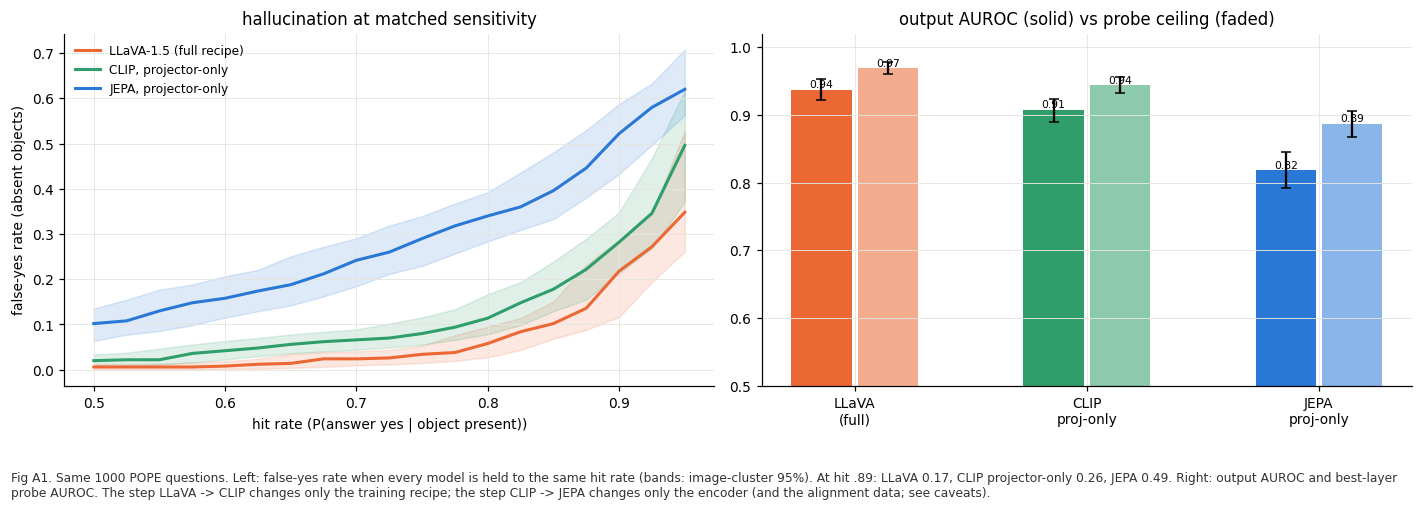


VERDICT on output AUROC: recipe share 0.25 [0.13, 0.38], encoder share 0.75.
  -> MOSTLY ENCODER (or its alignment data): a CLIP encoder aligned the same way as JEPA keeps most of LLaVA's performance, so the gap is mainly CLIP -> JEPA.


TypeError: 'Series' object is not callable

In [8]:
# A2. THREE-ARM ANALYSIS (CPU): LLaVA-1.5 full  ->  CLIP projector-only  ->  JEPA projector-only, on the same questions
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
C_L, C_C, C_J, C_G = "#eb6834", "#2f9e6b", "#2a78d6", "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e5e2", "grid.linewidth": 0.6, "figure.dpi": 110, "font.size": 9})
def finish(fig, name, caption):
    fig.tight_layout(rect=(0, 0.11, 1, 1)); fig.text(0.01, 0.005, caption, fontsize=8, va="bottom", wrap=True, color="#333333")
    fig.savefig(f"{OUT_DIR}/figs/{name}.png", dpi=130); plt.show(); plt.close(fig)
def LZ(name):
    p = f"{OUT_DIR}/{name}"; return dict(np.load(p, allow_pickle=True)) if os.path.exists(p) else None
def cluster_boot(group_ids, B=300, seed=0):
    codes, uniq = pd.factorize(np.asarray(group_ids)); members = [np.flatnonzero(codes == g) for g in range(len(uniq))]; rng = np.random.default_rng(seed)
    return [np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))]) for _ in range(B)]

ARMS = [("LLaVA-1.5 (full recipe)", "llava_clean.npz", C_L), ("CLIP, projector-only", "clip_clean.npz", C_C), ("JEPA, projector-only", "jepa_clean.npz", C_J)]
D = {nm: LZ(f) for nm, f, _ in ARMS}; COL = {nm: c for nm, _, c in ARMS}
print("available:", {nm: (d is not None) for nm, d in D.items()})
AN_OK = all(d is not None for d in D.values())
if not AN_OK: print(">>> a clean-pass file is missing (llava_clean.npz / jepa_clean.npz come from the first run: attach encoder-swap-compare); analysis skipped <<<")
else:
    q0 = [str(q) for q in D[ARMS[0][0]]["qids"]]
    for nm, d in D.items(): assert [str(q) for q in d["qids"]] == q0, f"{nm} was run on different questions"
    IMG_OF = {r["question_id"]: str(r["image_id"]) for r in recs}
    QC = q0; YC = np.array([g == "yes" for g in D[ARMS[0][0]]["gt"]]); GC = np.array([IMG_OF[q] for q in QC]); NC = len(QC); BOOT = cluster_boot(GC, BOOT_B); ALL = np.arange(NC)
    print(f"{NC} common questions, {len(set(GC))} images, {BOOT_B} image-cluster bootstrap draws")
    names = [a[0] for a in ARMS]; L, Cc, J = names

    # ---------- helpers ----------
    sgn = np.where(YC, 1.0, -1.0)
    def fy_at_hit(ld, y, h):
        thr = np.quantile(ld[y], 1 - h); return float((ld[~y] > thr).mean())          # false-yes rate at the threshold that gives hit rate h on present objects
    def margin(ld, ix): return float((sgn[ix] * ld[ix]).mean())
    def ci2(v): lo, hi = np.percentile(v, [2.5, 97.5]); return f"[{lo:+.3f}, {hi:+.3f}]"

    # ---------- probes (information decodable at the last position) ----------
    def probe_oof(R, l, C=0.02):
        X = R[:, l, :].astype(np.float32); oof = np.zeros(NC)
        for tr, te in GroupKFold(5).split(X, YC, GC):
            sc = StandardScaler().fit(X[tr]); clf = LogisticRegression(C=C, max_iter=300, class_weight="balanced").fit(sc.transform(X[tr]), YC[tr]); oof[te] = clf.decision_function(sc.transform(X[te]))
        return oof
    PR = {}; layers = [l for l in PROBE_LAYERS if l < D[L]["RES"].shape[1]]
    for nm in names:
        t0 = time.time(); _p = Prog(f"{nm} probes", len(layers), 0, 20); oofs = {}
        for _i, l in enumerate(layers): oofs[l] = probe_oof(D[nm]["RES"], l); _p(_i)
        au_l = {l: auroc(o, YC) for l, o in oofs.items()}; best = max(au_l, key=au_l.get); PR[nm] = dict(oof=oofs[best], best=best, by_layer=au_l)
        print(f"{nm}: best probe layer L{best} AUROC {au_l[best]:.3f} | {(time.time() - t0) / 60:.1f} min")

    # ---------- per-arm metrics (point + bootstrap) ----------
    def metrics(nm, ix):
        d = D[nm]; ld, lc = d["LD"][ix], d["LDC"][ix]; y = YC[ix]
        return dict(out_auroc=auroc(ld, y), ceiling=auroc(PR[nm]["oof"][ix], y), dprime=dprime(ld, y), margin=margin(d["LD"], ix),
                    fy_089=fy_at_hit(ld, y, 0.89), fy_080=fy_at_hit(ld, y, 0.80), fy_070=fy_at_hit(ld, y, 0.70), corr_auroc=auroc(lc, y))
    M0 = {nm: metrics(nm, ALL) for nm in names}; MB = {nm: pd.DataFrame([metrics(nm, b) for b in BOOT]) for nm in names}
    rows = []
    for nm in names:
        d = D[nm]; ld, lc = d["LD"], d["LDC"]; b = beh(ld, YC)
        rows.append({"arm": nm, "AUROC": M0[nm]["out_auroc"], "d'": M0[nm]["dprime"], "acc": b["acc"], "hit rate": 1 - b["miss"], "false-yes @0": b["halluc"], "yes-rate": b["yes_rate"],
                     "truthful margin": M0[nm]["margin"], "probe ceiling": M0[nm]["ceiling"], "info not used": M0[nm]["ceiling"] - M0[nm]["out_auroc"],
                     "false-yes @hit .70": M0[nm]["fy_070"], "false-yes @hit .80": M0[nm]["fy_080"], "false-yes @hit .89": M0[nm]["fy_089"]})
    T1 = pd.DataFrame(rows).set_index("arm"); print("\n=== T1. behaviour and information (same questions) ==="); print(T1.round(3).T.to_string())
    print("\n95% image-cluster CIs of the headline numbers:")
    for k, lab in (("out_auroc", "output AUROC"), ("ceiling", "probe ceiling"), ("margin", "truthful margin"), ("fy_089", "false-yes at hit .89")):
        print(f"  {lab:22s}", " | ".join(f"{nm.split(',')[0].split(' (')[0]}: {M0[nm][k]:.3f} {ci2(MB[nm][k])}" for nm in names))

    # ---------- prior-only (corrupted image) measures ----------
    from scipy.stats import spearmanr
    rows = []
    for nm in names:
        ld, lc = D[nm]["LD"], D[nm]["LDC"]; ab = ~YC; q = np.quantile(lc[ab], [1 / 3, 2 / 3]); t = np.digitize(lc[ab], q)
        rows.append({"arm": nm, "k (noise)": float(D[nm]["k"]), "corrupted AUROC": auroc(lc, YC), "corrupted yes-rate": float((lc > 0).mean()), "corrupted mean": float(lc.mean()), "clean sd": float(ld.std()),
                     "R2 clean~corrupted": float(np.corrcoef(ld, lc)[0, 1] ** 2), "spearman (absent)": float(spearmanr(ld[ab], lc[ab])[0]),
                     "false-yes low prior": float((ld[ab][t == 0] > 0).mean()), "false-yes mid prior": float((ld[ab][t == 1] > 0).mean()), "false-yes high prior": float((ld[ab][t == 2] > 0).mean())})
    T2 = pd.DataFrame(rows).set_index("arm"); print("\n=== T2. prior-only (corrupted-image) measures. NOTE: LLaVA's k was calibrated separately; CLIP and JEPA use the same k ==="); print(T2.round(3).T.to_string())

    # ---------- decomposition: how much of the LLaVA - JEPA gap is the training recipe, how much the encoder ----------
    print("\n=== T3. decomposition of the LLaVA - JEPA gap (recipe = LLaVA - CLIP; encoder = CLIP - JEPA) ===")
    DEC = {}
    for k, lab in (("out_auroc", "output AUROC"), ("ceiling", "probe ceiling (information)"), ("dprime", "d'"), ("margin", "truthful margin"), ("fy_089", "false-yes at hit .89")):
        tot = M0[L][k] - M0[J][k]; rec = M0[L][k] - M0[Cc][k]; enc = M0[Cc][k] - M0[J][k]
        sh = (MB[L][k] - MB[Cc][k]) / (MB[L][k] - MB[J][k]).replace(0, np.nan)
        DEC[k] = dict(label=lab, total=tot, recipe=rec, encoder=enc, recipe_share=rec / tot if tot else float("nan"), recipe_share_ci=tuple(np.nanpercentile(sh, [2.5, 97.5])))
        print(f"  {lab:30s} total {tot:+.3f} | recipe {rec:+.3f} | encoder {enc:+.3f} | recipe share {DEC[k]['recipe_share']:.2f} [{DEC[k]['recipe_share_ci'][0]:.2f}, {DEC[k]['recipe_share_ci'][1]:.2f}]")
    for a, b_, lab in ((L, Cc, "recipe step  (LLaVA -> CLIP projector-only)"), (Cc, J, "encoder step (CLIP -> JEPA)"), (L, J, "total        (LLaVA -> JEPA)")):
        dout = M0[a]["out_auroc"] - M0[b_]["out_auroc"]; dc = M0[a]["ceiling"] - M0[b_]["ceiling"]
        print(f"  information share of the output-AUROC drop, {lab}: {dc / dout if dout else float('nan'):.2f}  (ceiling drop {dc:+.3f} of output drop {dout:+.3f}; the first run found 0.69 for LLaVA -> JEPA)")

    # ---------- figures ----------
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6)); hs = np.linspace(0.5, 0.95, 19)
    for nm in names:
        pt = np.array([fy_at_hit(D[nm]["LD"], YC, h) for h in hs]); bt = np.array([[fy_at_hit(D[nm]["LD"][b], YC[b], h) for h in hs] for b in BOOT]); lo, hi = np.percentile(bt, [2.5, 97.5], axis=0)
        ax[0].plot(hs, pt, color=COL[nm], lw=2, label=nm); ax[0].fill_between(hs, lo, hi, color=COL[nm], alpha=0.15)
    ax[0].set_xlabel("hit rate (P(answer yes | object present))"); ax[0].set_ylabel("false-yes rate (absent objects)"); ax[0].set_title("hallucination at matched sensitivity"); ax[0].legend(frameon=False, fontsize=8)
    xs = np.arange(3); w = 0.26
    for j, (k, lab) in enumerate((("out_auroc", "output AUROC"), ("ceiling", "probe ceiling"))):
        v = [M0[nm][k] for nm in names]; e = [np.percentile(MB[nm][k], [2.5, 97.5]) for nm in names]
        ax[1].bar(xs + (j - 0.5) * w * 1.1, v, w, color=[COL[nm] for nm in names], alpha=0.55 if j else 1.0, yerr=[[a - b[0] for a, b in zip(v, e)], [b[1] - a for a, b in zip(v, e)]], capsize=3, label=lab)
        for x_, v_ in zip(xs + (j - 0.5) * w * 1.1, v): ax[1].text(x_, v_, f"{v_:.2f}", ha="center", va="bottom", fontsize=7)
    ax[1].set_xticks(xs); ax[1].set_xticklabels(["LLaVA\n(full)", "CLIP\nproj-only", "JEPA\nproj-only"]); ax[1].set_ylim(0.5, 1.02); ax[1].set_title("output AUROC (solid) vs probe ceiling (faded)")
    finish(fig, "A1_three_arms", f"Fig A1. Same {NC} POPE questions. Left: false-yes rate when every model is held to the same hit rate (bands: image-cluster 95%). At hit .89: LLaVA {M0[L]['fy_089']:.2f}, CLIP projector-only {M0[Cc]['fy_089']:.2f}, JEPA {M0[J]['fy_089']:.2f}. Right: output AUROC and best-layer probe AUROC. The step LLaVA -> CLIP changes only the training recipe; the step CLIP -> JEPA changes only the encoder (and the alignment data; see caveats).")

    def _md(df):
        cols = list(df.columns); out = ["| |" + "|".join(str(c) for c in cols) + "|", "|---|" + "|".join("---" for _ in cols) + "|"]
        for i, r in df.iterrows(): out.append(f"| {i} |" + "|".join(str(r[c]) for c in cols) + "|")
        return "\n".join(out)
    # ---------- verdict ----------
    s = DEC["out_auroc"]; enc_share = 1 - s["recipe_share"]
    _lo, _hi = s["recipe_share_ci"]
    if not (0 <= s["recipe_share"] <= 1) or (_hi - _lo) > 1.0: reading = "NOT A CLEAN DECOMPOSITION: the arms are not ordered LLaVA > CLIP > JEPA, or the share is poorly determined (wide CI). Read the three arms directly in T1 instead of the share."
    elif enc_share >= 0.6: reading = "MOSTLY ENCODER (or its alignment data): a CLIP encoder aligned the same way as JEPA keeps most of LLaVA's performance, so the gap is mainly CLIP -> JEPA."
    elif enc_share <= 0.4: reading = "MOSTLY RECIPE: a CLIP encoder aligned projector-only already drops to near JEPA's level, so most of the LLaVA -> JEPA gap comes from the training recipe (jointly tuned LM), not the encoder."
    else: reading = "MIXED: both the recipe and the encoder contribute."
    print(f"\nVERDICT on output AUROC: recipe share {s['recipe_share']:.2f} [{s['recipe_share_ci'][0]:.2f}, {s['recipe_share_ci'][1]:.2f}], encoder share {enc_share:.2f}.\n  -> {reading}")
    CLIP_RES = dict(T1=T1.round(4).to_dict(), T2=T2.round(4).to_dict(), decomposition={k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in v.items()} for k, v in DEC.items()}, n_questions=NC, layout=CLIP_LAYOUT, k_clip=CLIP_K, probe_best_layer={nm: PR[nm]["best"] for nm in names}, verdict=reading)
    with open(f"{OUT_DIR}/clip_control_results.json", "w") as f: json.dump(CLIP_RES, f, indent=1, default=float)
    with open(f"{OUT_DIR}/clip_control_report.md", "w") as f:
        f.write("# Control A: CLIP encoder aligned projector-only vs JEPA vs LLaVA-1.5 (same %d POPE object questions)\n\n" % NC)
        f.write("Arms: LLaVA-1.5-7B (full recipe, fp16); CLIP ViT-L/14-336 -> LLaVA-1.5 stage-1 projector -> frozen 4-bit Vicuna-7B-v1.5 (layout %s); I-JEPA ViT-H/16 -> our projector -> frozen 4-bit Vicuna-7B-v1.5.\n\n## T1 behaviour and information\n\n" % CLIP_LAYOUT)
        f.write(_md(T1.round(3).T) + "\n\n## T2 prior-only measures\n\n" + _md(T2.round(3).T) + "\n\n## T3 decomposition (recipe = LLaVA - CLIP, encoder = CLIP - JEPA)\n\n")
        f.write("| metric | total | recipe | encoder | recipe share [95% CI] |\n|---|---|---|---|---|\n")
        for k, v in DEC.items(): f.write(f"| {v['label']} | {v['total']:+.3f} | {v['recipe']:+.3f} | {v['encoder']:+.3f} | {v['recipe_share']:.2f} [{v['recipe_share_ci'][0]:.2f}, {v['recipe_share_ci'][1]:.2f}] |\n")
        f.write(f"\n**Reading:** {reading}\n\n## Caveats\n- The CLIP stage-1 projector was trained on ~558K captions; the JEPA projector on 5,000. The CLIP -> JEPA step therefore mixes encoder and alignment-data scale.\n- One projector per arm, one seed; the bootstrap covers question sampling, not training variance.\n- The CLIP projector was trained with layout [BOS][image][text]; the JEPA one with [image][BOS][text]. Layout used here: %s.\n- LLaVA runs in fp16 and its corruption strength was calibrated separately; CLIP and JEPA use the same k=%.2f, in 4-bit.\n" % (CLIP_LAYOUT, CLIP_K))
    push("clip control results")

In [11]:
import subprocess
OUT="/kaggle/working/encoder_swap"
def sh(cmd, timeout=600):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    return r.returncode, (r.stdout + r.stderr)

import os
print(sorted(os.listdir(OUT)))   # expect clip_clean.npz, clip_control_results.json, clip_control_report.md, figs
push("clip control results")

['01_behaviour.png', '02_dla_mlp.png', '03_dla_heads.png', '04_dla_groups.png', '05_probes.png', '06_ablation.png', 'ckpt_clean_clip.npz', 'clip_clean.npz', 'clip_control_report.md', 'clip_control_results.json', 'compare_report.md', 'compare_results.json', 'dataset-metadata.json', 'figs', 'jepa_clean.npz', 'llava_ablation.npz', 'llava_clean.npz', 'llava_patching.npz']
[push] OK (clip control results): :00<?, ?B/s]
100%|██████████| 8.69k/8.69k [00:00<00:00, 33.5kB/s]

  0%|          | 0.00/127k [00:00<?, ?B/s]
100%|██████████| 127k/127k [00:00<00:00, 489kB/s]

